In [1]:
import numpy as np
import pandas as pd 

import os
import glob
import matplotlib.pyplot as plt

from tqdm import tqdm

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim

import torchvision.io as io
import torchvision.models as models
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

In [6]:
import zipfile
import os

zip_path = '/Users/seomichelle/26-2 ESAA:Python/dataset/state-farm-distracted-driver-detection.zip'
extract_path = '/Users/seomichelle/26-2 ESAA:Python/dataset'

# 압축 파일 내에서 train/ 폴더 아래에 있는 파일만 필터링해서 압축을 풉니다.
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    # 압축 파일 내 모든 파일 목록 가져오기
    all_files = zip_ref.namelist()

    # 'train/' 혹은 'imgs/train/' 등 train 경로를 포함하는 파일만 필터링
    # zip 파일 구조에 맞게 필터링 조건을 설정합니다.
    train_files = [f for f in all_files if 'train/' in f]

    if train_files:
        print(f"총 {len(train_files)}개의 train 관련 파일을 압축 해제 중입니다...")
        for file in tqdm(train_files):
            zip_ref.extract(file, path=extract_path)
        print("압축 해제가 완료되었습니다!")
    else:
        print("압축 파일 내에서 'train/' 경로를 찾을 수 없습니다. 파일 목록 중 일부를 출력합니다:")
        print(all_files[:10])

총 22424개의 train 관련 파일을 압축 해제 중입니다...


100%|██████████| 22424/22424 [00:02<00:00, 7873.10it/s]

압축 해제가 완료되었습니다!


In [7]:
train_path = '/kaggle/input/state-farm-distracted-driver-detection/imgs/train'
for folder in glob.glob(train_path+'/*'):
    folder_name = folder.split('/')[-1]
    print(f'{folder_name} : {len(os.listdir(folder))} images')

In [11]:
for folder in glob.glob(train_path+'/*'):
    if os.path.isdir(folder):
        show_images(folder, 6)

> Data is almost balanced

In [12]:
classes = {
    'c0': 'safe driving',
    'c1': 'texting - right',
    'c2': 'talking on the phone - right',
    'c3': 'texting - left',
    'c4': 'talking on the phone - left',
    'c5': 'operating the radio',
    'c6': 'drinking',
    'c7': 'reaching behind',
    'c8': 'hair and makeup',
    'c9': 'talking to passenger'
}


In [13]:
def show_images(folder_path, num):
    """
    Description:
        Display a random selection of images from the specified folder path.

    Parameters:
        - folder_path (str): The path to the folder containing the images.
        - num (int): The number of images to display.

    Returns:
        None
    """
    images = glob.glob(folder_path+'/*')
    selected_images = np.random.choice(images, num, replace=False)
    
    fig = plt.figure(figsize=(10, 6))
    columns = 3
    rows = (len(selected_images) // columns) + 1
    for i, image_file in enumerate(selected_images):
        img = plt.imread(image_file)
        ax = fig.add_subplot(rows, columns, i+1)
        ax.imshow(img)
        ax.axis('off')
    class_ = folder_path.split('/')[-1]
    plt.suptitle(classes[class_])
    plt.show()

# show some random images from each class 
for folder in glob.glob(train_path+'/*'):
    show_images(folder, 6)


In [19]:
img_path = '/Users/seomichelle/26-2 ESAA:Python/dataset/imgs/train/c1/img_100021.jpg'
img = io.read_image(img_path)
img.shape

torch.Size([3, 480, 640])

In [16]:
class BaselineDenseModel(nn.Module):
    def __init__(self, input_size, num_classes):
        super(BaselineDenseModel, self).__init__()
        self.fc1 = nn.Linear(input_size, 256)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, 64)
        self.fc4 = nn.Linear(64, 32)
        self.fc5 = nn.Linear(32, num_classes)
        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=1)
        
    def forward(self, x):
        x = x.view(x.size(0), -1) # flatten the input
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.relu(self.fc3(x))
        x = self.relu(self.fc4(x))
        x = self.fc5(x)
        return self.softmax(x)


input_size = 480*640*3
num_classes = 10

model = BaselineDenseModel(input_size, num_classes)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters())

In [17]:
train_transform = transforms.Compose([
    transforms.Resize((480, 640)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(degrees=10),
    transforms.RandomAffine(degrees=0, translate=(0.1,0.1), scale=(1.0, 1.2)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((480, 640)),  
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


In [21]:
train_path = '/Users/seomichelle/26-2 ESAA:Python/dataset/imgs/train'
dataset = datasets.ImageFolder(root=train_path, transform=train_transform)

In [22]:
dataset

Dataset ImageFolder
    Number of datapoints: 22424
    Root location: /Users/seomichelle/26-2 ESAA:Python/dataset/imgs/train
    StandardTransform
Transform: Compose(
               Resize(size=(480, 640), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
               RandomAffine(degrees=[0.0, 0.0], translate=(0.1, 0.1), scale=(1.0, 1.2))
               ToTensor()
               Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
           )

In [23]:
class2idx = dataset.class_to_idx
class_indices = {v:k for k, v in class2idx.items()}
class_indices

{0: 'c0',
 1: 'c1',
 2: 'c2',
 3: 'c3',
 4: 'c4',
 5: 'c5',
 6: 'c6',
 7: 'c7',
 8: 'c8',
 9: 'c9'}

In [24]:
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

In [25]:
# Split the dataset into training and validation sets
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

In [26]:
train_dataset.dataset.transform = train_transform
val_dataset.dataset.transform = test_transform

In [27]:
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

In [28]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cpu'

In [29]:
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=10, device='cuda'):
    """
    Description:
        Train the given model using the provided data loaders and optimization parameters.

    Parameters:
        - model (torch.nn.Module): The neural network model to train.
        - train_loader (torch.utils.data.DataLoader): DataLoader for training data.
        - val_loader (torch.utils.data.DataLoader): DataLoader for validation data.
        - criterion (torch.nn.Module): The loss function.
        - optimizer (torch.optim.Optimizer): The optimizer used for updating model parameters.
        - num_epochs (int): Number of training epochs (default: 10).
        - device (str): Device to run the training on (default: 'cuda').

    Returns:
        - model (torch.nn.Module): The trained model.
        - history (dict): A dictionary containing training history with keys:
            - 'train_loss': List of training losses for each epoch.
            - 'train_acc': List of training accuracies for each epoch.
            - 'val_loss': List of validation losses for each epoch.
            - 'val_acc': List of validation accuracies for each epoch.

    """
    
    model.to(device)
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    
    for epoch in tqdm(range(num_epochs)):
        # Training phase
        model.train()
        train_loss = 0.0
        correct_train = 0
        total_train_images = 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            _, predicted = torch.max(outputs.data, dim=1)
            correct_train += (predicted == labels).sum().item()
            total_train_images += labels.size(0)
            

        train_accuracy = 100 * correct_train / total_train_images
        avg_train_loss = train_loss / len(train_loader)

        # Validation phase
        model.eval()
        val_loss = 0.0
        correct_val = 0
        total_val_images = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item()
                _, predicted = torch.max(outputs.data, 1)
                correct_val += (predicted == labels).sum().item()
                total_val_images += labels.size(0)
                

        val_accuracy = 100 * correct_val / total_val_images
        avg_val_loss = val_loss / len(val_loader)

        # Print epoch statistics
        print(f"Epoch [{epoch+1}/{num_epochs}]\nTrain Loss: {avg_train_loss:.4f}, Train Acc: {train_accuracy:.2f}%, Val Loss: {avg_val_loss:.4f}, Val Acc: {val_accuracy:.2f}%")

        # Save history
        history['train_loss'].append(avg_train_loss)
        history['train_acc'].append(train_accuracy)
        history['val_loss'].append(avg_val_loss)
        history['val_acc'].append(val_accuracy)

    return model, history


In [ ]:
def plot_performance(history):
    """
    Description:
        Plot the training and validation loss, as well as training and validation accuracy over epochs.

    Parameters:
        - history (dict): A dictionary containing training history with keys:
        - 'train_loss': List of training losses for each epoch.
        - 'train_acc': List of training accuracies for each epoch.
        - 'val_loss': List of validation losses for each epoch.
        - 'val_acc': List of validation accuracies for each epoch.

    Returns:
        None
    """
    
    epochs = range(1, len(history['train_loss']) + 1)

    # Plot loss
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history['train_loss'], 'b-', label='Training Loss')
    plt.plot(epochs, history['val_loss'], 'r-', label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    # Plot accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, history['train_acc'], 'b-', label='Training Accuracy')
    plt.plot(epochs, history['val_acc'], 'r-', label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy (%)')
    plt.legend()

    plt.tight_layout()
    plt.show()

In [ ]:
class BaselineCNN(nn.Module):
    def __init__(self, num_classes):
        super(BaselineCNN, self).__init__()
        self.conv=nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, stride=1, padding=1)
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.fc1 = nn.Linear(64 * 37 * 37, 512)  # Adjusted input size based on the output of conv2
        self.fc2 = nn.Linear(512, num_classes)

    # def forward(self, x):
    #     identity=torch.relu(self.conv(x))
    #     x = torch.relu(self.conv1(x))
    #     x = (torch.relu(self.conv2(x))
    #     x=self.pool(self.pool(x+identity))
        
    #     x = x.view(-1, 64 * 37 * 37)  # Adjusted reshape based on the output size of conv2
    #     x = torch.relu(self.fc1(x))
    #     x = self.fc2(x)
    #     return x
    def forward(self, x):
        # identity path (projection to 64 channels)
        identity = torch.relu(self.conv(x))        # (B, 64, H, W)
    
        # residual path
        out = torch.relu(self.conv1(x))             # (B, 32, H, W)
        out = torch.relu(self.conv2(out))           # (B, 64, H, W)
    
        # residual addition (shapes now match)
        out = out + identity
    
        # downsampling AFTER residual addition
        out = self.pool(self.pool(out))
    
        out = out.view(out.size(0), -1)
        out = torch.relu(self.fc1(out))
        out = self.fc2(out)
    
        return out


model = BaselineCNN(num_classes=10)

In [32]:
train_transform = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(degrees=10),
    transforms.RandomAffine(degrees=0, translate=(0.1,0.1), scale=(1.0, 1.2)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((150, 150)),  
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


In [33]:
dataset = datasets.ImageFolder(root=train_path, transform=train_transform)

In [34]:
dataset

Dataset ImageFolder
    Number of datapoints: 22424
    Root location: /Users/seomichelle/26-2 ESAA:Python/dataset/imgs/train
    StandardTransform
Transform: Compose(
               Resize(size=(150, 150), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
               RandomAffine(degrees=[0.0, 0.0], translate=(0.1, 0.1), scale=(1.0, 1.2))
               ToTensor()
               Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
           )

In [35]:
class2idx = dataset.class_to_idx
class_indices = {v:k for k, v in class2idx.items()}
class_indices

{0: 'c0',
 1: 'c1',
 2: 'c2',
 3: 'c3',
 4: 'c4',
 5: 'c5',
 6: 'c6',
 7: 'c7',
 8: 'c8',
 9: 'c9'}

In [36]:
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

In [37]:
# Split the dataset into training and validation sets
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

In [38]:
train_dataset.dataset.transform = train_transform
val_dataset.dataset.transform = test_transform

In [39]:
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

In [40]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters())

In [ ]:
trained_model, history = train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=6, device=device)

  0%|          | 0/6 [00:00<?, ?it/s]

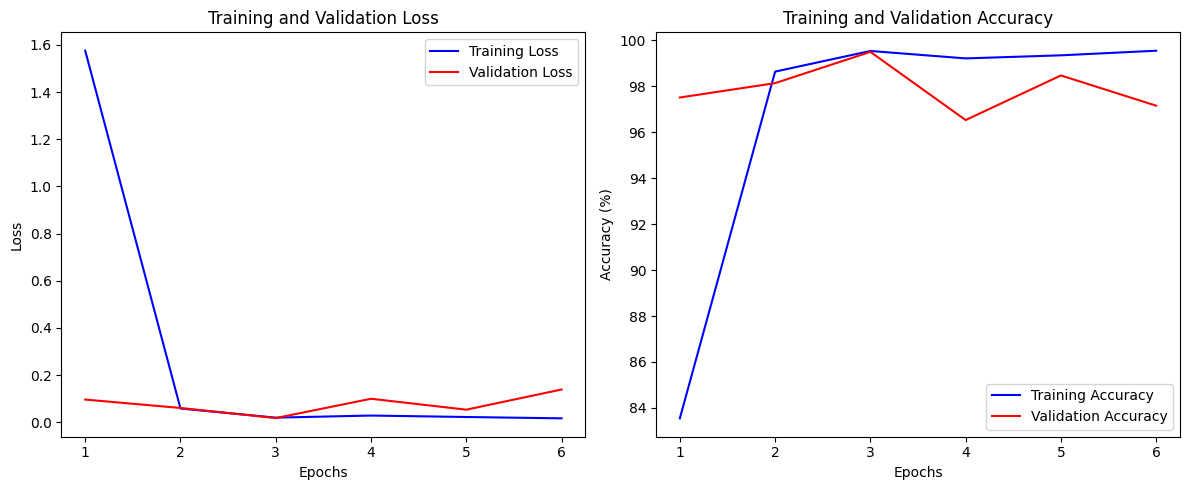

In [ ]:
plot_performance(history)

In [30]:
def predict_folder(folder_path, model):
    probabilities_per_image = []
    images = []

    for img_path in glob.glob(folder_path+'/*'):
        image = Image.open(img_path)
        image = test_transform(image).unsqueeze(0) # batch dimension
        
        model.eval()
        with torch.no_grad():
            image = image.to(device)
            output = model(image)

        # Apply softmax to obtain probabilities
        probabilities = torch.softmax(output, dim=1)
        probabilities = probabilities.squeeze(0).tolist()

        images.append(img_path.split('/')[-1])
        probabilities_per_image.append(probabilities)

    return images, probabilities_per_image


In [31]:
# Example usage
folder_path = '/kaggle/input/state-farm-distracted-driver-detection/imgs/test'
images, probabilities_per_image = predict_folder(folder_path, trained_model)

In [32]:
len(probabilities_per_image)

79726

In [33]:
df1 = pd.DataFrame({'img': images})
df2 = pd.DataFrame(probabilities_per_image, columns = ['c0', 'c1', 'c2', 'c3', 'c4', 'c5', 'c6', 'c7', 'c8', 'c9'])
final_sub = pd.concat((df1, df2), axis=1)
final_sub

,img,c0,c1,c2,c3,c4,c5,c6,c7,c8,c9
0,img_96590.jpg,2.965542e-10,3.382078e-08,2.113799e-09,8.446015e-13,9.307095e-09,7.397045e-13,7.201862e-09,1.755784e-08,1.000000e+00,1.828033e-12
1,img_32366.jpg,8.309938e-08,2.026264e-08,1.562669e-07,1.189704e-07,9.325628e-01,6.275059e-03,7.151387e-05,9.115152e-07,4.925700e-04,6.059659e-02
2,img_99675.jpg,8.841494e-04,7.779583e-03,4.781697e-07,2.228868e-07,1.523869e-03,6.255750e-07,1.852620e-07,7.558861e-03,2.584463e-04,9.819935e-01
3,img_85937.jpg,1.516439e-08,1.264895e-13,8.620137e-15,3.076735e-12,9.998651e-01,1.348097e-04,2.287270e-11,4.971010e-11,2.660808e-09,9.704011e-08
4,img_73903.jpg,2.965947e-11,6.392199e-10,1.765621e-08,1.622245e-14,2.100677e-08,1.031091e-14,2.457494e-10,1.000000e+00,1.869853e-08,1.612955e-10
...,...,...,...,...,...,...,...,...,...,...,...
79721,img_109.jpg,1.207873e-06,6.842073e-05,3.613671e-03,2.230073e-04,4.837795e-01,1.586284e-05,3.527242e-10,1.773134e-04,5.068655e-01,5.255554e-03
79722,img_53257.jpg,1.889278e-06,7.804010e-08,1.648720e-09,9.950399e-01,4.246216e-03,3.663602e-11,3.963917e-09,1.020988e-06,7.108906e-04,6.015812e-08
79723,img_90376.jpg,3.541887e-17,9.999971e-01,8.629412e-09,4.502394e-07,9.245289e-12,1.729092e-16,2.356311e-06,6.729944e-09,8.282307e-11,1.409059e-09
79724,img_28000.jpg,6.139109e-07,2.009473e-05,3.467135e-05,4.714514e-04,1.331705e-04,2.811089e-05,5.363936e-04,2.461263e-06,9.906325e-01,8.140410e-03


In [34]:
final_sub.isnull().sum()

img    0
c0     0
c1     0
c2     0
c3     0
c4     0
c5     0
c6     0
c7     0
c8     0
c9     0
dtype: int64

In [35]:
final_sub.to_csv('final_sub.csv', index=False)

In [36]:
transfer_model = models.resnet18(pretrained=True)
num = transfer_model.fc.in_features
transfer_model.fc = nn.Linear(num, 10)

trained_transfer_model, history = train_model(transfer_model, train_loader, val_loader, criterion, optimizer, num_epochs=6)

/opt/conda/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:00<00:00, 142MB/s]
 17%|█▋        | 1/6 [02:41<13:26, 161.27s/it]

Epoch [1/6]
Train Loss: 2.4904, Train Acc: 11.36%, Val Loss: 2.5176, Val Acc: 11.13%


 33%|███▎      | 2/6 [05:03<09:59, 149.85s/it]

Epoch [2/6]
Train Loss: 2.4907, Train Acc: 11.21%, Val Loss: 2.5232, Val Acc: 11.24%


 50%|█████     | 3/6 [07:26<07:21, 147.06s/it]

Epoch [3/6]
Train Loss: 2.4895, Train Acc: 11.28%, Val Loss: 2.5245, Val Acc: 11.24%


... (2 outputs left out)

 83%|████████▎ | 5/6 [12:12<02:24, 144.49s/it]

Epoch [5/6]
Train Loss: 2.4916, Train Acc: 11.18%, Val Loss: 2.5231, Val Acc: 11.04%


100%|██████████| 6/6 [14:34<00:00, 145.77s/it]

Epoch [6/6]
Train Loss: 2.4910, Train Acc: 11.13%, Val Loss: 2.5185, Val Acc: 11.24%


> Now, We will ignore the previous accuracy and loss😂 and say that the best model for this problem is simple CNN.